# 05 · Customer segmentation (K-Means)

**Goal:** group customers into a few profiles that the business can act on, then cross them with churn risk.
Features: `tenure`, `MonthlyCharges`, `NumServices` (scaled).

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # lets the notebook import src/

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config

sns.set_theme(style="whitegrid")
ACCENT = "#941B50"
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from src.segment import default_names, fit_segments, save_segments

df = pd.read_csv(config.CLEAN_DATA)
X_seg = StandardScaler().fit_transform(df[config.SEGMENT_FEATURES])

## 1. How many segments? (elbow + silhouette)

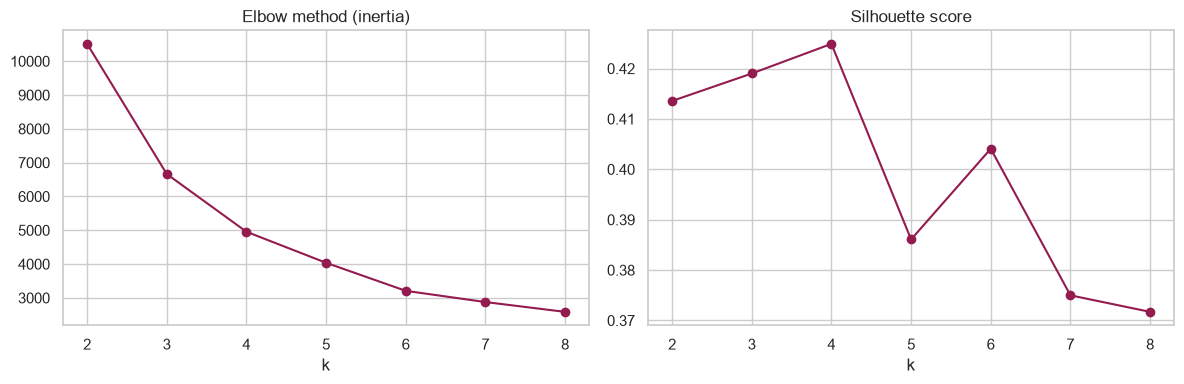

In [3]:
ks = range(2, 9)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=config.RANDOM_STATE).fit(X_seg)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_seg, km.labels_, sample_size=3000, random_state=config.RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertia, marker="o", color=ACCENT); axes[0].set_title("Elbow method (inertia)"); axes[0].set_xlabel("k")
axes[1].plot(list(ks), silhouette, marker="o", color=ACCENT); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "05_choose_k.png", dpi=150); plt.show()

## 2. Fit and profile the segments

In [4]:
scaler, kmeans = fit_segments(df, k=config.N_SEGMENTS)
df["cluster"] = kmeans.labels_

profile = df.groupby("cluster").agg(
    customers=("customerID", "size"),
    tenure=("tenure", "mean"),
    monthly_charges=("MonthlyCharges", "mean"),
    services=("NumServices", "mean"),
    churn_rate=("Churn", "mean"),
    month_to_month=("Contract", lambda s: (s == "Month-to-month").mean()),
).round(2)
profile

,customers,tenure,monthly_charges,services,churn_rate,month_to_month
cluster,,,,,,
0,972,54.47,30.13,2.06,0.04,0.16
1,2410,14.92,77.30,4.25,0.47,0.86
2,2152,57.44,91.30,6.72,0.16,0.26
3,1509,10.25,29.21,1.66,0.24,0.72


## 3. Name the segments

In [10]:
names = default_names(df, df["cluster"])
names

{0: 'Loyal, low bill',
 1: 'New, high bill',
 2: 'Loyal, high bill',
 3: 'New, low bill'}

In [11]:
names = {0: "Stable basic", 1: "New & high bill", 2: "Loyal premium", 3: "Price-sensitive starters"}
names

{0: 'Stable basic',
 1: 'New & high bill',
 2: 'Loyal premium',
 3: 'Price-sensitive starters'}

In [12]:
df["Segment"] = df["cluster"].map(names)
summary = df.groupby("Segment").agg(customers=("customerID", "size"), churn_rate=("Churn", "mean"),
                                    avg_monthly=("MonthlyCharges", "mean")).sort_values("churn_rate", ascending=False)
summary.style.format({"churn_rate": "{:.1%}", "avg_monthly": "${:.0f}"})

,customers,churn_rate,avg_monthly
Segment,,,
New & high bill,2410,47.0%,$77
Price-sensitive starters,1509,23.9%,$29
Loyal premium,2152,15.6%,$91
Stable basic,972,4.1%,$30


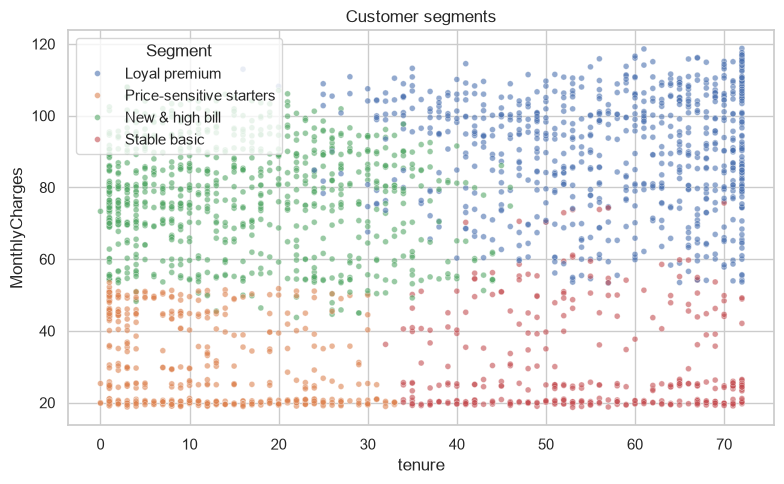

In [13]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df.sample(2500, random_state=1), x="tenure", y="MonthlyCharges", hue="Segment", alpha=0.6, s=18)
plt.title("Customer segments")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "05_segments.png", dpi=150); plt.show()

## 4. Save the segmentation and create the Power BI file

In [14]:
save_segments(scaler, kmeans, names)

from src import score
score.main()  # writes data/processed/customers_scored.csv

Saved 7,043 scored customers to C:\Users\USER\Desktop\churn-retention-dashboard\data\processed\customers_scored.csv
RiskLevel
Low       4089
High      1488
Medium    1466
Monthly revenue at risk: $138,823
Expected churners (sum of probabilities): 1,869 | actual churners: 1,869


In [15]:
scored = pd.read_csv(config.SCORED_DATA)
scored.groupby(["Segment", "RiskLevel"]).size().unstack(fill_value=0)

RiskLevel,High,Low,Medium
Segment,,,
Loyal premium,102,1633,417
New & high bill,1162,625,623
Price-sensitive starters,224,892,393
Stable basic,0,939,33
